# EN4554 Assignment 2 — Task 3: Regularization and Residual Connections

**Name:** _your name_  **Index number:** _your index_

**GitHub:** https://github.com/chamudiR/EN4554-Assignment-2-on-CNNs

<a href="https://colab.research.google.com/github/chamudiR/EN4554-Assignment-2-on-CNNs/blob/main/Task3_Regularization_ResNets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Use of AI tools:** Claude (Anthropic) was used to help write the code in this notebook. I have gone through and understood all of it.

**Runtime:** Colab T4 GPU (*Runtime → Change runtime type → T4 GPU*). Measured times:
* **3(a):** 7 methods × 3 seeds × 100 epochs on 5k images, about 15 min (about 43 s per run).
* **3(b):** 6 networks × 30 epochs on 45k images, about 25 min (plain-8 ≈ 75 s, plain-20 ≈ 165 s, plain-56 ≈ 7.5 min, and similar for the residual networks).

Downloading CIFAR-10 can take longer than the training itself when the download server is slow (up to 47 min in my runs).

If time is short, reduce `SEEDS_3A` or `EPOCHS_3B`. The training loops skip runs that have already finished, so if a cell is interrupted, re-running it continues where it stopped (as long as the Colab runtime was not reset).

## 0. Setup

This uses the same data pipeline as Tasks 1 and 2:
* Fixed seeds.
* **45 000 train / 5 000 validation** split.
* Per-channel normalisation with statistics from the **training split only**.
* The **test set is not loaded**.

All data stays on the GPU, and augmentations are implemented as batched tensor operations on the GPU. Training uses mixed precision (`torch.autocast` with float16 and a `GradScaler`), which uses the T4's tensor cores and speeds up training roughly 2×.

In [ ]:
import math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.benchmark = True       # fastest conv algorithms; runs are seeded but not bit-reproducible

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('PyTorch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

PyTorch 2.11.0+cu130 | device: cuda | Tesla T4


In [ ]:
# ---- Load CIFAR-10 training set and make the 45k / 5k split (identical to Tasks 1 and 2) ----
train_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
CLASSES = train_full.classes

X_all = torch.from_numpy(train_full.data).float().div(255).permute(0, 3, 1, 2)  # (50000, 3, 32, 32) in [0, 1]
y_all = torch.tensor(train_full.targets, dtype=torch.long)

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val,   y_val   = X_all[val_idx],   y_all[val_idx]

# ---- Per-channel normalisation with TRAINING statistics only ----
mean = X_train.mean(dim=(0, 2, 3))
std  = X_train.std(dim=(0, 2, 3))
X_train = (X_train - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)
X_val   = (X_val   - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)

Xtr, ytr = X_train.to(device), y_train.to(device)
Xva, yva = X_val.to(device),   y_val.to(device)

# ---- 5k training subset for 3(a): 500 images per class, drawn from the 45k training split ----
g = torch.Generator().manual_seed(SEED)
idx5k = torch.cat([torch.nonzero(y_train == c).squeeze(1)[torch.randperm(int((y_train == c).sum()), generator=g)[:500]]
                   for c in range(10)])
X5k, y5k = Xtr[idx5k.to(device)], ytr[idx5k.to(device)]

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape), '| 5k subset', tuple(X5k.shape))
print('5k subset class counts:', torch.bincount(y5k, minlength=10).tolist())

100%|██████████| 170M/170M [43:15<00:00, 65.7kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | 5k subset (5000, 3, 32, 32)
5k subset class counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


## Shared training utilities

**Augmentations.** Each one works on a whole mini-batch on the GPU and draws different random parameters for every image.

* **Flip + crop** (standard CIFAR augmentation). Each image is flipped horizontally with probability ½. It is then zero-padded by 4 pixels on each side and a random 32×32 crop is taken. After normalisation, zero is the mean pixel.
* **Cutout** (DeVries & Taylor, 2017; my implementation). A 16×16 square is set to zero in every image. Its centre is uniform over the image, so the square may be partly outside the image, as in the paper. The network can no longer rely on any single local region, such as a dog's face, and has to use the whole object.
* **Mixup** (Zhang et al., 2018; my implementation). Draw $\lambda \sim \mathrm{Beta}(\alpha, \alpha)$ once per batch, with $\alpha = 1$ for CIFAR-10 as in the paper. Pair each image with a random other image in the batch, train on $\tilde x = \lambda x_i + (1-\lambda) x_j$, and use the loss $\lambda\,\mathrm{CE}(f(\tilde x), y_i) + (1-\lambda)\,\mathrm{CE}(f(\tilde x), y_j)$. This is equivalent to training on soft labels $\lambda y_i + (1-\lambda) y_j$. It encourages the network to behave linearly between training examples and discourages over-confident, memorised decision boundaries.

**Training loop.** The optimizer is SGD with momentum 0.9. The learning-rate schedule is cosine annealing to 0, with an optional linear warm-up, and it is updated every step. Mixed precision is used.

Training *accuracy* is measured on the **clean (un-augmented) training images in eval mode** at the end of every epoch. The running accuracy on augmented or mixed batches would not be comparable between methods, and with mixup it is not even well defined.

In [ ]:
def random_flip_crop(x, pad=4):
    n, c, h, w = x.shape
    dev = x.device
    flip = torch.rand(n, device=dev) < 0.5
    x = torch.where(flip.view(n, 1, 1, 1), x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))                       # zero = mean pixel after normalisation
    i = torch.randint(0, 2 * pad + 1, (n,), device=dev)        # top-left corner of each crop
    j = torch.randint(0, 2 * pad + 1, (n,), device=dev)
    rows = (i.view(n, 1) + torch.arange(h, device=dev)).view(n, 1, h, 1)
    cols = (j.view(n, 1) + torch.arange(w, device=dev)).view(n, 1, 1, w)
    return xp[torch.arange(n, device=dev).view(n, 1, 1, 1), torch.arange(c, device=dev).view(1, c, 1, 1), rows, cols]


def cutout(x, size=16):
    n, _, h, w = x.shape
    dev = x.device
    cy = torch.randint(0, h, (n, 1, 1), device=dev)            # centre of the square, anywhere in the image
    cx = torch.randint(0, w, (n, 1, 1), device=dev)
    ys = torch.arange(h, device=dev).view(1, h, 1)
    xs = torch.arange(w, device=dev).view(1, 1, w)
    hole = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~hole).unsqueeze(1).to(x.dtype)                # (n, 1, h, w) mask broadcast over channels


def mixup(x, y, alpha=1.0):
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

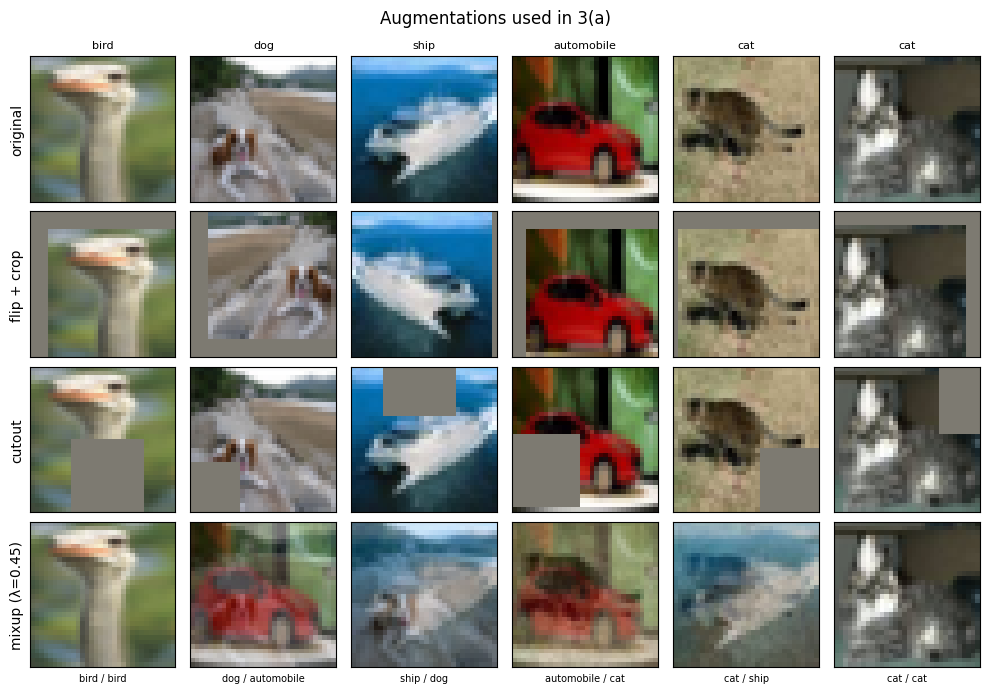

In [ ]:
# Visual check of the augmentations on a few training images
def to_img(x):
    return (x.cpu() * std.view(3, 1, 1) + mean.view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).numpy()

set_seed(0)
show = torch.randperm(len(X5k), generator=torch.Generator().manual_seed(0))[:6].to(device)  # X5k is sorted by class
xs, ys = X5k[show], y5k[show]
mixed, ya, yb, lam = mixup(xs, ys)
rows = [('original', xs), ('flip + crop', random_flip_crop(xs)), ('cutout', cutout(xs)), (f'mixup (λ={lam:.2f})', mixed)]
fig, ax = plt.subplots(4, 6, figsize=(10, 7))
for r, (name, batch) in enumerate(rows):
    for c in range(6):
        ax[r, c].imshow(to_img(batch[c])); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        if r == 3:
            ax[r, c].set_xlabel(f'{CLASSES[ya[c]]} / {CLASSES[yb[c]]}', fontsize=7)
        elif r == 0:
            ax[r, c].set_title(CLASSES[ys[c]], fontsize=8)
    ax[r, 0].set_ylabel(name)
plt.suptitle('Augmentations used in 3(a)'); plt.tight_layout(); plt.show()

In [ ]:
@torch.no_grad()
def evaluate(model, X, y, batch=1000):
    model.eval()
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), batch):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out = model(X[i:i + batch])
        loss_sum += F.cross_entropy(out.float(), y[i:i + batch], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + batch]).sum().item()
    return loss_sum / len(X), correct / len(X)


def train_run(model, X, y, epochs, lr, weight_decay=0.0, batch_size=128, augment=(), mixup_alpha=0.0,
              warmup_epochs=0, eval_train=False, seed=SEED, log_every=0):
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    steps_per_epoch = math.ceil(len(X) / batch_size)
    total, warm = epochs * steps_per_epoch, warmup_epochs * steps_per_epoch

    def lr_factor(step):                                       # linear warm-up, then cosine decay to 0
        if step < warm:
            return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    gen = torch.Generator().manual_seed(seed)                  # mini-batch order
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(X), generator=gen).to(X.device)
        loss_sum = torch.zeros((), device=X.device)
        for i in range(0, len(X), batch_size):
            idx = order[i:i + batch_size]
            xb, yb = X[idx], y[idx]
            for aug in augment:
                xb = aug(xb)
            if mixup_alpha > 0:
                xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(xb)
                if mixup_alpha > 0:
                    loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb2)
                else:
                    loss = F.cross_entropy(out, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            loss_sum += loss.detach().float() * len(idx)
        hist['train_loss'].append(loss_sum.item() / len(X))   # on the (augmented) training batches
        if eval_train:
            hist['train_acc'].append(evaluate(model, X, y)[1])  # clean images, eval mode
        vl, va = evaluate(model, Xva, yva)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if log_every and (ep % log_every == 0 or ep == epochs):
            tr = f' train acc {hist["train_acc"][-1]:.4f} |' if eval_train else ''
            print(f'    epoch {ep:3d} | train loss {hist["train_loss"][-1]:.4f} |{tr} val acc {va:.4f} | {time.time() - t0:.0f}s')
    hist['time'] = time.time() - t0
    return hist

## Task 3(a): Regularization on a 5k-image training set

**Model.** The model is a small CNN with batch norm:
* Two conv blocks at 32 channels, then max-pool.
* Two conv blocks at 64 channels, then max-pool.
* One conv block at 128 channels, then max-pool.
* FC 2048 → 256 → 10.

Each conv block is Conv3×3 → BN → ReLU. The model has about 670k parameters, far more than 5k images can constrain, so the baseline is expected to overfit heavily.

**Setup.**
* **Data:** 5 000 training images (500 per class); the full 5k validation split is used.
* **Training:** SGD with momentum 0.9, lr 0.05 with cosine decay, batch size 128, **100 epochs**.
* **Seeds:** each method is run with **3 seeds** (initialisation and batch order). The table reports mean ± standard deviation.

| Method | What changes |
|---|---|
| baseline | nothing |
| weight decay | L2 penalty $5\times10^{-4}$ (through SGD's `weight_decay`) |
| dropout | `Dropout(0.5)` before both fully connected layers |
| flip+crop | random horizontal flip + 4-pixel-padded random crop |
| cutout | one 16×16 square zeroed per image |
| mixup | $\alpha = 1$ |
| all combined | weight decay + dropout + flip+crop + cutout + mixup |

Dropout is placed only in the classifier, after the last BN layer. Dropout before a BN layer changes the activation variance between training and evaluation ("variance shift"), which hurts BN networks.

In [ ]:
class SmallBNCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        def block(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
        self.features = nn.Sequential(
            *block(3, 32),  *block(32, 32), nn.MaxPool2d(2),     # 32 -> 16
            *block(32, 64), *block(64, 64), nn.MaxPool2d(2),     # 16 -> 8
            *block(64, 128),                nn.MaxPool2d(2))     # 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(128 * 4 * 4, 256), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


print('SmallBNCNN parameters:', sum(p.numel() for p in SmallBNCNN().parameters()))

CONFIGS_3A = {
    'baseline':     dict(),
    'weight decay': dict(weight_decay=5e-4),
    'dropout':      dict(dropout=0.5),
    'flip+crop':    dict(augment=(random_flip_crop,)),
    'cutout':       dict(augment=(cutout,)),
    'mixup':        dict(mixup_alpha=1.0),
    'all combined': dict(weight_decay=5e-4, dropout=0.5, augment=(random_flip_crop, cutout), mixup_alpha=1.0),
}
EPOCHS_3A = 100
SEEDS_3A = [0, 1, 2]
results3a = {}

SmallBNCNN parameters: 666858


In [ ]:
for name, cfg in CONFIGS_3A.items():
    for seed in SEEDS_3A:
        if (name, seed) in results3a:                      # already done (allows resuming)
            continue
        set_seed(seed)
        model = SmallBNCNN(dropout=cfg.get('dropout', 0.0)).to(device)
        h = train_run(model, X5k, y5k, EPOCHS_3A, lr=0.05,
                      weight_decay=cfg.get('weight_decay', 0.0), augment=cfg.get('augment', ()),
                      mixup_alpha=cfg.get('mixup_alpha', 0.0), eval_train=True, seed=seed)
        results3a[(name, seed)] = h
        print(f'{name:>13} seed {seed} | train acc {h["train_acc"][-1] * 100:6.2f}% | '
              f'val acc {h["val_acc"][-1] * 100:6.2f}% (best {max(h["val_acc"]) * 100:6.2f}%) | {h["time"]:.0f}s')

     baseline seed 0 | train acc 100.00% | val acc  66.08% (best  66.62%) | 43s
     baseline seed 1 | train acc 100.00% | val acc  66.40% (best  67.50%) | 38s
     baseline seed 2 | train acc 100.00% | val acc  68.14% (best  68.62%) | 38s
 weight decay seed 0 | train acc 100.00% | val acc  67.08% (best  67.80%) | 39s
 weight decay seed 1 | train acc 100.00% | val acc  66.92% (best  67.40%) | 40s
 weight decay seed 2 | train acc 100.00% | val acc  67.98% (best  68.44%) | 41s
      dropout seed 0 | train acc  99.74% | val acc  70.74% (best  70.92%) | 41s
      dropout seed 1 | train acc  99.82% | val acc  71.24% (best  71.58%) | 41s
      dropout seed 2 | train acc  99.92% | val acc  70.40% (best  70.46%) | 41s
    flip+crop seed 0 | train acc  98.72% | val acc  76.52% (best  76.84%) | 42s
    flip+crop seed 1 | train acc  98.86% | val acc  75.34% (best  75.62%) | 42s
    flip+crop seed 2 | train acc  98.90% | val acc  75.66% (best  76.08%) | 42s
       cutout seed 0 | train acc 100.00%

In [ ]:
def stat(name, key, fn=lambda v: v[-1]):
    return np.array([fn(results3a[(name, s)][key]) for s in SEEDS_3A]) * 100

rows = []
for name in CONFIGS_3A:
    tr, va = stat(name, 'train_acc'), stat(name, 'val_acc')
    gap, best = tr - va, stat(name, 'val_acc', max)
    rows.append({'method': name,
                 'train acc (%)': f'{tr.mean():.2f} ± {tr.std():.2f}',
                 'val acc (%)':   f'{va.mean():.2f} ± {va.std():.2f}',
                 'gap (train − val)': f'{gap.mean():.2f} ± {gap.std():.2f}',
                 'best val acc (%)': f'{best.mean():.2f} ± {best.std():.2f}'})
table3a = pd.DataFrame(rows)
print(f'Final-epoch accuracies after {EPOCHS_3A} epochs, mean ± std over seeds {SEEDS_3A}. '
      'Train accuracy is measured on clean training images.')
display(table3a)

Final-epoch accuracies after 100 epochs, mean ± std over seeds [0, 1, 2]. Train accuracy is measured on clean training images.


,method,train acc (%),val acc (%),gap (train − val),best val acc (%)
0,baseline,100.00 ± 0.00,66.87 ± 0.91,33.13 ± 0.91,67.58 ± 0.82
1,weight decay,100.00 ± 0.00,67.33 ± 0.47,32.67 ± 0.47,67.88 ± 0.43
2,dropout,99.83 ± 0.07,70.79 ± 0.34,29.03 ± 0.38,70.99 ± 0.46
3,flip+crop,98.83 ± 0.08,75.84 ± 0.50,22.99 ± 0.57,76.18 ± 0.50
4,cutout,100.00 ± 0.00,69.62 ± 0.71,30.38 ± 0.71,69.93 ± 0.70
5,mixup,99.98 ± 0.02,66.61 ± 0.14,33.37 ± 0.12,67.51 ± 0.49
6,all combined,72.91 ± 0.42,67.19 ± 0.31,5.73 ± 0.33,68.22 ± 0.46


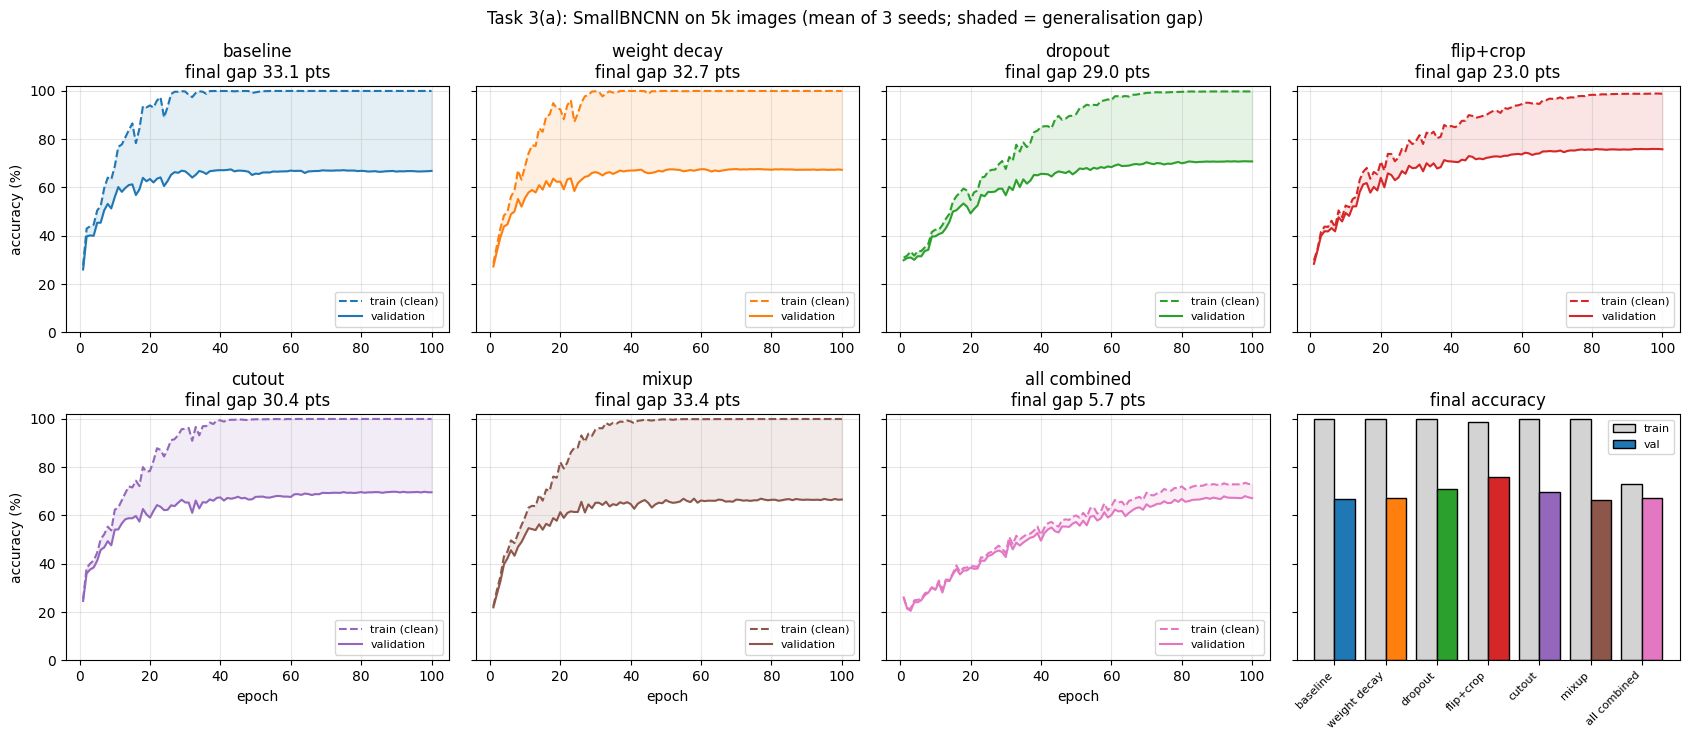

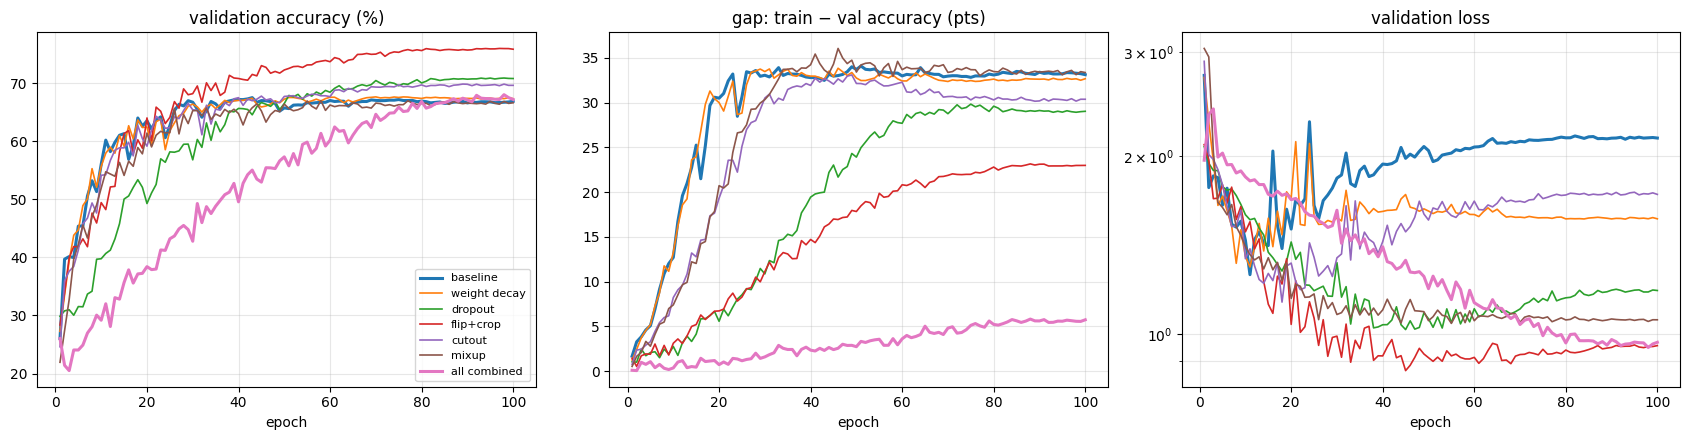

In [ ]:
def curve(name, key):
    return np.mean([results3a[(name, s)][key] for s in SEEDS_3A], axis=0) * 100

ep = np.arange(1, EPOCHS_3A + 1)
colors = {n: f'C{i}' for i, n in enumerate(CONFIGS_3A)}

# Small multiples: train vs val accuracy for each method
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharey=True)
for ax, name in zip(axes.flat, CONFIGS_3A):
    tr, va = curve(name, 'train_acc'), curve(name, 'val_acc')
    ax.plot(ep, tr, color=colors[name], ls='--', label='train (clean)')
    ax.plot(ep, va, color=colors[name], label='validation')
    ax.fill_between(ep, va, tr, color=colors[name], alpha=0.12)
    ax.set_title(f'{name}\nfinal gap {tr[-1] - va[-1]:.1f} pts')
    ax.set_ylim(0, 102); ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=8)
for ax in axes[1, :3]:
    ax.set_xlabel('epoch')
for ax in axes[:, 0]:
    ax.set_ylabel('accuracy (%)')

ax = axes[1, 3]                                            # 8th panel: summary bar chart
x = np.arange(len(CONFIGS_3A))
tr_f = [stat(n, 'train_acc').mean() for n in CONFIGS_3A]
va_f = [stat(n, 'val_acc').mean() for n in CONFIGS_3A]
ax.bar(x - 0.2, tr_f, 0.4, color='lightgrey', edgecolor='k', label='train')
ax.bar(x + 0.2, va_f, 0.4, color=[colors[n] for n in CONFIGS_3A], edgecolor='k', label='val')
ax.set_xticks(x); ax.set_xticklabels(CONFIGS_3A, rotation=45, ha='right', fontsize=8)
ax.set_title('final accuracy'); ax.legend(fontsize=8)
fig.suptitle(f'Task 3(a): SmallBNCNN on 5k images (mean of {len(SEEDS_3A)} seeds; shaded = generalisation gap)')
plt.tight_layout(); plt.show()

# Overlays: validation accuracy, generalisation gap and validation loss
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name in CONFIGS_3A:
    lw = 2.2 if name in ('baseline', 'all combined') else 1.2
    ax[0].plot(ep, curve(name, 'val_acc'), color=colors[name], lw=lw, label=name)
    ax[1].plot(ep, curve(name, 'train_acc') - curve(name, 'val_acc'), color=colors[name], lw=lw, label=name)
    ax[2].plot(ep, curve(name, 'val_loss') / 100, color=colors[name], lw=lw, label=name)
ax[0].set_title('validation accuracy (%)'); ax[1].set_title('gap: train − val accuracy (pts)')
ax[2].set_title('validation loss'); ax[2].set_yscale('log')
for a in ax:
    a.set_xlabel('epoch'); a.grid(alpha=0.3, which='both')
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**

Final-epoch results after 100 epochs (mean ± std over 3 seeds; training accuracy is on clean images):

| method | train acc (%) | val acc (%) | gap (pts) | val acc vs baseline |
|---|---|---|---|---|
| baseline | 100.00 | 66.87 ± 0.91 | 33.1 | — |
| weight decay | 100.00 | 67.33 ± 0.47 | 32.7 | +0.5 |
| dropout | 99.83 | 70.79 ± 0.34 | 29.0 | +3.9 |
| **flip+crop** | 98.83 | **75.84 ± 0.50** | 23.0 | **+9.0** |
| cutout | 100.00 | 69.62 ± 0.71 | 30.4 | +2.8 |
| mixup | 99.98 | 66.61 ± 0.14 | 33.4 | −0.3 |
| all combined | 72.91 | 67.19 ± 0.31 | **5.7** | +0.3 |

* **Baseline: the network memorises the training set.** With about 667k parameters and only 5k images, it reaches 100% training accuracy by about epoch 30 but only 67% validation accuracy, a gap of 33 points. Its validation loss starts rising after about epoch 20, because it becomes over-confident on validation images it gets wrong.
* **Noise.** The seed-to-seed standard deviation is 0.1–0.9 points, so differences below about 1 point (weight decay, mixup, all combined) are not meaningful. The gains from flip+crop, dropout and cutout are clearly real. Running the whole notebook twice gave the same ranking, with every number changing by less than 1 point.
* **Flip + crop: by far the best (+9.0 points, 75.8%).** A flipped or slightly shifted image still shows the same object, so every training image yields many new, valid variations. This effectively gives the network more data.
* **Dropout: second best (+3.9 points).** Dropout is applied to the fully connected layers, which hold 79% of the parameters. It slows memorisation: training accuracy approaches 100% only around epoch 70, against epoch 30 for the baseline.
* **Cutout: a moderate gain (+2.8 points).** A 16×16 square covers up to a quarter of a 32×32 image, often hiding much of the object. That is a strong change for a small network trained for only 100 epochs, so it helps less than flip + crop.
* **Weight decay: no real effect on accuracy (+0.5, within noise).** It mainly lowers the validation loss (about 1.55 against 2.1). With batch norm, the conv layers do not depend on the size of their weights, so weight decay restricts them very little.
* **Mixup: no accuracy gain, but much better calibrated.** Accuracy is unchanged (66.6% vs 66.9%), but the validation loss halves (about 1.05 against 2.1). Training on mixed images and labels makes the network less over-confident, even though its predicted classes hardly change.
* **All combined: the smallest gap (5.7), but it underfits.** Training accuracy drops to 72.9%, and validation accuracy (67.2%) is 8.7 points *below* flip + crop alone. Five regularisers together are too strong for this small network and 100 epochs. The gap shrank because training accuracy fell, not because validation accuracy rose.
* **Lessons.**
  * **The best regulariser** is the one that matches real properties of the images (flip + crop).
  * **A small gap does not mean the best accuracy.**
  * **Regularisers should be combined selectively.** For example, flip + crop with dropout for Task 4.

## Task 3(b): Plain vs residual networks of depth $6n+2$ (8, 20, 56)

**Architecture.** CIFAR-style networks as in He et al. (2016), §4.2:
* Conv3×3(16) → BN → ReLU.
* Three stages of $n$ blocks with 16, 32 and 64 channels. Feature maps are 32×32, 16×16 and 8×8. The first block of stages 2 and 3 halves the resolution with stride 2.
* Global average pooling, then FC 64 → 10.

Each block is Conv3×3 → BN → ReLU → Conv3×3 → BN, followed by a final ReLU, and contributes 2 weight layers. The depth is therefore $1 + 6n + 1 = 6n + 2$, giving $n = 1, 3, 9$ for depths 8, 20 and 56.

**The only difference is the shortcut.**
* Residual block: $\mathrm{ReLU}(F(x) + \text{shortcut}(x))$.
* Plain block: $\mathrm{ReLU}(F(x))$.

The shortcut is the identity. Where the shape changes, it uses the paper's *option A*: subsample with stride 2 and zero-pad the extra channels. Option A has **no parameters**, so each plain network and its residual counterpart have *exactly* the same parameter count and initial weights.

**Initialisation.** Conv and FC weights use Kaiming normal (fan-out, ReLU). BN starts with $\gamma = 1, \beta = 0$.

**Training.**
* **Data:** all 45k training images, with flip + crop augmentation as in the paper.
* **Optimizer:** SGD with momentum 0.9, lr 0.1, weight decay $10^{-4}$, batch size 128.
* **Schedule:** 1 epoch of linear warm-up, then cosine decay over **30 epochs**.
* All six networks use the same seed and the same settings.

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.residual = residual
        self.extra_ch = cout - cin
        self.stride = stride

    def shortcut(self, x):
        # Option A: identity; when the shape changes, subsample and zero-pad channels (no parameters)
        if self.stride != 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra_ch > 0:
            x = F.pad(x, (0, 0, 0, 0, self.extra_ch // 2, self.extra_ch - self.extra_ch // 2))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)          # the ONLY difference between plain and residual
        return F.relu(out)


class CifarNet(nn.Module):
    def __init__(self, depth, residual):
        super().__init__()
        assert (depth - 2) % 6 == 0, 'depth must be 6n + 2'
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        blocks, cin = [], 16
        for stage, cout in enumerate([16, 32, 64]):
            for b in range(n):
                stride = 2 if (stage > 0 and b == 0) else 1
                blocks.append(BasicBlock(cin, cout, stride, residual))
                cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():                  # Kaiming initialisation
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)  # global average pooling
        return self.fc(x)


DEPTHS = [8, 20, 56]
for d in DEPTHS:
    n_weight_layers = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in CifarNet(d, True).modules())
    print(f'depth {d:2d}: weight layers = {n_weight_layers}, params plain = {sum(p.numel() for p in CifarNet(d, False).parameters()):,}, '
          f'params residual = {sum(p.numel() for p in CifarNet(d, True).parameters()):,}')

depth  8: weight layers = 8, params plain = 75,290, params residual = 75,290
depth 20: weight layers = 20, params plain = 269,722, params residual = 269,722
depth 56: weight layers = 56, params plain = 853,018, params residual = 853,018


### Gradient norms at initialisation (56 layers)

Before training, I look at the gradient each block receives, as in Task 1(d). This is $\lVert \partial L/\partial W\rVert$ for the first conv of each of the 27 blocks of the 56-layer networks, computed from one batch of 512 training images with the same initial weights for both networks.

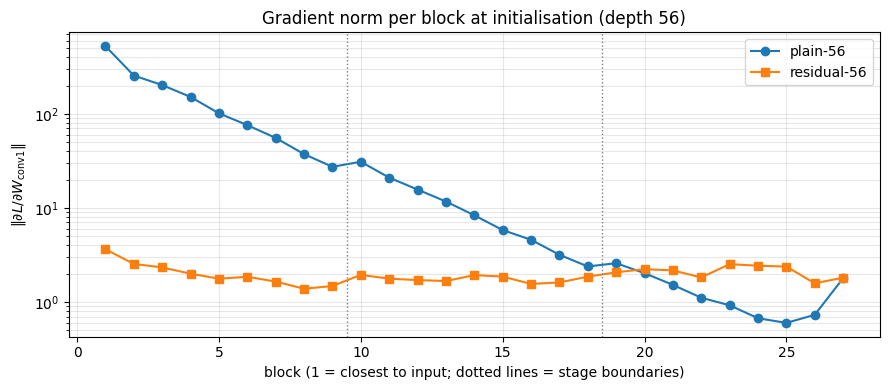

first/last block gradient ratio: plain 2.93e+02, residual 2.01e+00


In [ ]:
def block_grad_norms(residual, depth=56, seed=SEED):
    set_seed(seed)
    model = CifarNet(depth, residual).to(device).train()
    loss = F.cross_entropy(model(Xtr[:512]), ytr[:512])
    loss.backward()
    return [b.conv1.weight.grad.norm().item() for b in model.blocks]

gn_plain, gn_res = block_grad_norms(False), block_grad_norms(True)
plt.figure(figsize=(9, 4))
plt.semilogy(range(1, 28), gn_plain, 'o-', label='plain-56')
plt.semilogy(range(1, 28), gn_res, 's-', label='residual-56')
for b in (9.5, 18.5):
    plt.axvline(b, color='grey', ls=':', lw=1)
plt.xlabel('block (1 = closest to input; dotted lines = stage boundaries)')
plt.ylabel(r'$\|\partial L/\partial W_{\mathrm{conv1}}\|$')
plt.title('Gradient norm per block at initialisation (depth 56)'); plt.grid(alpha=0.3, which='both'); plt.legend()
plt.tight_layout(); plt.show()
print(f'first/last block gradient ratio: plain {gn_plain[0] / gn_plain[-1]:.2e}, residual {gn_res[0] / gn_res[-1]:.2e}')

**Interpretation of the initialisation plot.**

* **Plain-56: the gradients *explode* towards the input.**
  * **Size:** the first block's gradient is about 530 and the last block's about 1.8, a ratio of **293**, growing roughly 1.24× per block.
  * **Cause:** this is the opposite of Task 1(d), where sigmoid made gradients vanish. Here batch norm in a deep network *without* shortcuts makes gradients grow layer by layer (Yang et al., 2019).
  * **Consequence:** with a single learning rate, the early layers receive updates hundreds of times too large while the late layers barely move. This makes the network hard to train.
* **Residual-56: an almost flat profile.** All 27 blocks receive gradients between about 1.4 and 3.7, a ratio of only **2.0**. The identity shortcut carries the gradient straight back to every block.
* **The shortcut is the only difference.** Both networks start from identical weights and have the same number of parameters (853,018). The difference in gradient flow therefore comes entirely from the shortcut. This predicts that plain-56 will be much harder to train than residual-56, which the training curves below test.

In [ ]:
EPOCHS_3B = 30
results3b = {}

In [ ]:
for residual in (False, True):
    for depth in DEPTHS:
        key = ('residual' if residual else 'plain', depth)
        if key in results3b:                                  # already done (allows resuming)
            continue
        print(f'=== {key[0]}-{depth} ===')
        set_seed(SEED)                                         # identical init for plain and residual
        model = CifarNet(depth, residual).to(device)
        results3b[key] = train_run(model, Xtr, ytr, EPOCHS_3B, lr=0.1, weight_decay=1e-4,
                                   augment=(random_flip_crop,), warmup_epochs=1, log_every=5)

=== plain-8 ===
    epoch   5 | train loss 0.7861 | val acc 0.7094 | 14s
    epoch  10 | train loss 0.6164 | val acc 0.7198 | 26s
    epoch  15 | train loss 0.5228 | val acc 0.8118 | 38s
    epoch  20 | train loss 0.4446 | val acc 0.8268 | 49s
    epoch  25 | train loss 0.3935 | val acc 0.8402 | 61s
    epoch  30 | train loss 0.3703 | val acc 0.8448 | 72s
=== plain-20 ===


/tmp/ipykernel_1049/3960974170.py:50: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    epoch   5 | train loss 0.7929 | val acc 0.6202 | 26s
    epoch  10 | train loss 0.5719 | val acc 0.7500 | 53s
    epoch  15 | train loss 0.4541 | val acc 0.8112 | 79s
    epoch  20 | train loss 0.3430 | val acc 0.8460 | 106s
    epoch  25 | train loss 0.2528 | val acc 0.8656 | 132s
    epoch  30 | train loss 0.2214 | val acc 0.8714 | 158s
=== plain-56 ===
    epoch   5 | train loss 1.7511 | val acc 0.3890 | 70s
    epoch  10 | train loss 1.4491 | val acc 0.4786 | 142s
    epoch  15 | train loss 1.1500 | val acc 0.5606 | 214s
    epoch  20 | train loss 0.9066 | val acc 0.6828 | 284s
    epoch  25 | train loss 0.7298 | val acc 0.7356 | 355s
    epoch  30 | train loss 0.6579 | val acc 0.7542 | 426s
=== residual-8 ===
    epoch   5 | train loss 0.8078 | val acc 0.6960 | 12s
    epoch  10 | train loss 0.6408 | val acc 0.7358 | 25s
    epoch  15 | train loss 0.5516 | val acc 0.7864 | 37s
    epoch  20 | train loss 0.4749 | val acc 0.8238 | 50s
    epoch  25 | train loss 0.4158 | val acc 

/tmp/ipykernel_1049/1799105612.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  a.set_xlabel('epoch'); a.grid(alpha=0.3, which='both'); a.legend(fontsize=8)


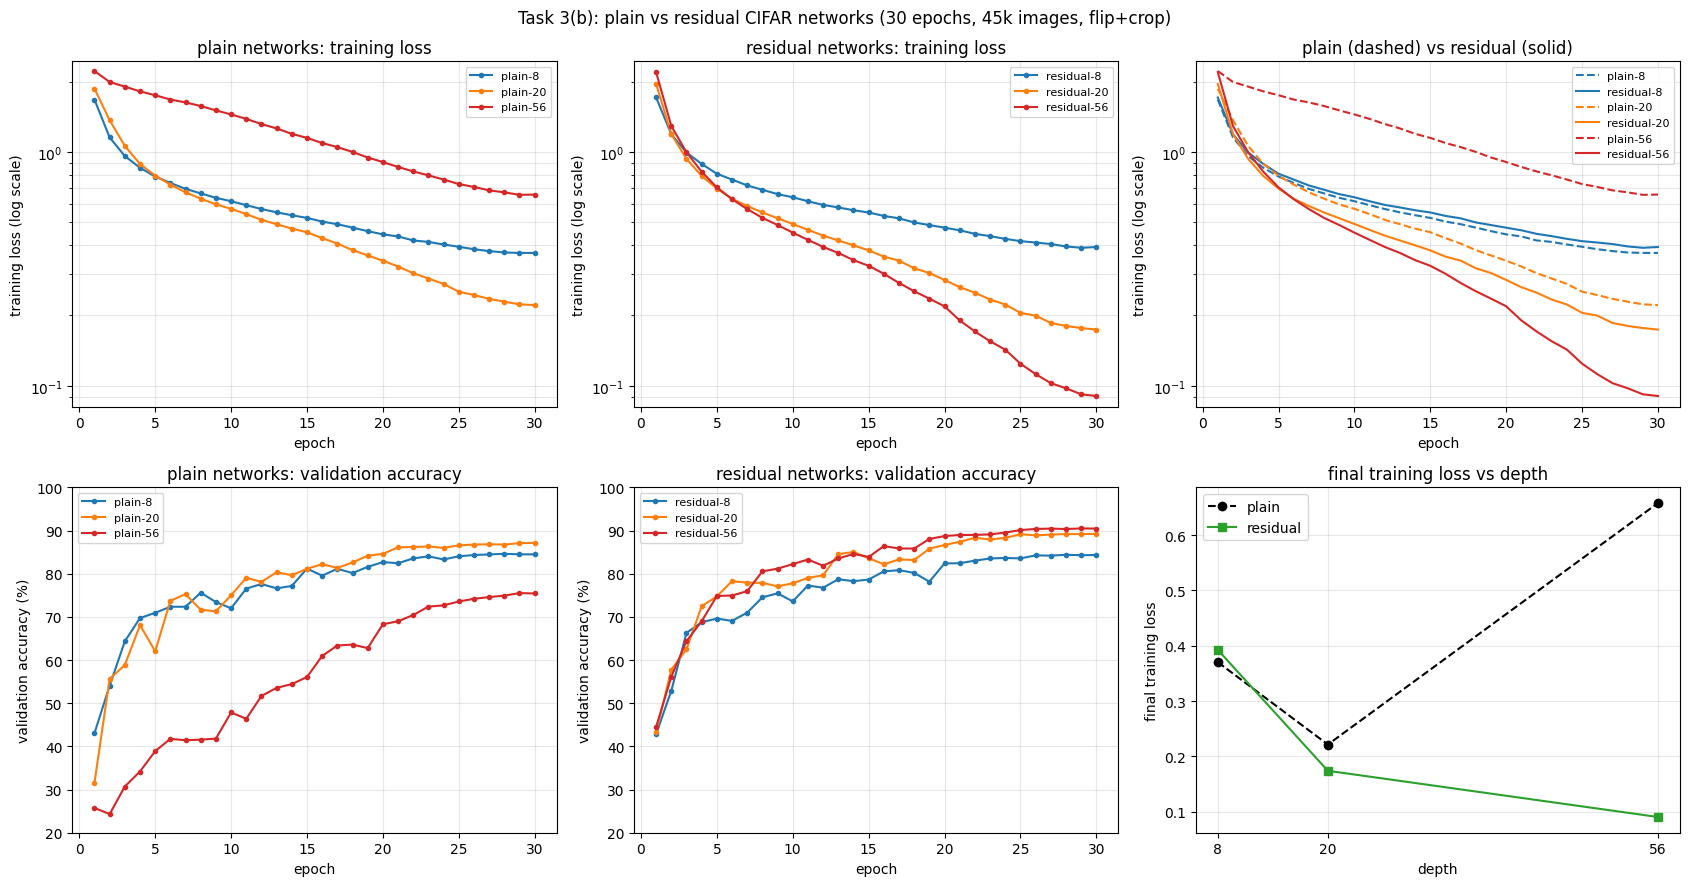

,network,params,train loss (epoch 1),train loss (epoch 5),final train loss,final val acc (%),time (s)
0,plain-8,75290,1.6765,0.7861,0.3703,84.48,72
1,plain-20,269722,1.8688,0.7929,0.2214,87.14,158
2,plain-56,853018,2.2225,1.7511,0.6579,75.42,426
3,residual-8,75290,1.7122,0.8078,0.3926,84.32,75
4,residual-20,269722,1.9550,0.6984,0.1740,89.22,166
5,residual-56,853018,2.1973,0.7062,0.0904,90.44,446


In [ ]:
ep = np.arange(1, EPOCHS_3B + 1)
dcol = {8: 'C0', 20: 'C1', 56: 'C3'}

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for j, fam in enumerate(['plain', 'residual']):
    for d in DEPTHS:
        h = results3b[(fam, d)]
        ax[0, j].plot(ep, h['train_loss'], 'o-', ms=3, color=dcol[d], label=f'{fam}-{d}')
        ax[1, j].plot(ep, np.array(h['val_acc']) * 100, 'o-', ms=3, color=dcol[d], label=f'{fam}-{d}')
    ax[0, j].set_title(f'{fam} networks: training loss'); ax[1, j].set_title(f'{fam} networks: validation accuracy')

for d in DEPTHS:                                            # 3rd column: direct plain vs residual comparison
    ax[0, 2].plot(ep, results3b[('plain', d)]['train_loss'], '--', color=dcol[d], label=f'plain-{d}')
    ax[0, 2].plot(ep, results3b[('residual', d)]['train_loss'], '-', color=dcol[d], label=f'residual-{d}')
ax[0, 2].set_title('plain (dashed) vs residual (solid)')

for j in range(3):
    ax[0, j].set_yscale('log'); ax[0, j].set_ylabel('training loss (log scale)')
for j in range(2):
    ax[1, j].set_ylabel('validation accuracy (%)'); ax[1, j].set_ylim(20, 100)
for a in ax.flat:
    a.set_xlabel('epoch'); a.grid(alpha=0.3, which='both'); a.legend(fontsize=8)
ymin = min(min(h['train_loss']) for h in results3b.values()) * 0.9
ymax = max(h['train_loss'][0] for h in results3b.values()) * 1.1
for j in range(3):
    ax[0, j].set_ylim(ymin, ymax)                           # same scale for all loss panels

ax[1, 2].plot(DEPTHS, [results3b[('plain', d)]['train_loss'][-1] for d in DEPTHS], 'o--', color='k', label='plain')
ax[1, 2].plot(DEPTHS, [results3b[('residual', d)]['train_loss'][-1] for d in DEPTHS], 's-', color='C2', label='residual')
ax[1, 2].set_xticks(DEPTHS); ax[1, 2].set_xlabel('depth'); ax[1, 2].set_ylabel('final training loss')
ax[1, 2].set_title('final training loss vs depth'); ax[1, 2].legend()
fig.suptitle(f'Task 3(b): plain vs residual CIFAR networks ({EPOCHS_3B} epochs, 45k images, flip+crop)')
plt.tight_layout(); plt.show()

display(pd.DataFrame([{'network': f'{fam}-{d}',
                       'params': sum(p.numel() for p in CifarNet(d, fam == 'residual').parameters()),
                       'train loss (epoch 1)': round(results3b[(fam, d)]['train_loss'][0], 4),
                       'train loss (epoch 5)': round(results3b[(fam, d)]['train_loss'][min(4, EPOCHS_3B - 1)], 4),
                       'final train loss': round(results3b[(fam, d)]['train_loss'][-1], 4),
                       'final val acc (%)': round(results3b[(fam, d)]['val_acc'][-1] * 100, 2),
                       'time (s)': round(results3b[(fam, d)]['time'])}
                      for fam in ('plain', 'residual') for d in DEPTHS]))

**Interpretation.**

| depth | plain: final train loss | residual: final train loss | plain: val acc (%) | residual: val acc (%) |
|---|---|---|---|---|
| 8 | 0.370 | 0.393 | 84.5 | 84.3 |
| 20 | 0.221 | 0.174 | 87.1 | 89.2 |
| 56 | **0.658** | **0.090** | **75.4** | **90.4** |

* **Plain networks: going deeper stops helping.**
  * **8 → 20 layers helps:** training loss 0.37 → 0.22, validation accuracy 84.5% → 87.1%.
  * **56 layers is much worse:** its training loss (0.66) is 3× that of plain-20, and its validation accuracy falls to 75.4%. This is the *training* loss, so it is not overfitting: the deeper network fits even the training data worse. This is the **degradation problem** described by He et al.
  * **Why it is a training problem, not a capacity problem:** plain-56 could in principle copy plain-20 and make its extra 36 layers do nothing, but SGD does not find such a solution.
  * **Slow start:** plain-56 also learns very slowly at the start. Its validation accuracy is stuck around 41% from epoch 6 to 9 and only passes 50% at epoch 12.
* **Residual networks: deeper is better.** The training loss falls steadily with depth (0.39 → 0.17 → 0.09), and validation accuracy rises (84.3% → 89.2% → 90.4%). Residual-56 is the best of all six networks. Each residual block only has to learn a small correction that is added to its input. If a block is not useful, it can stay close to zero, so extra depth does not hurt.
* **The benefit of the shortcut grows with depth.**
  * **Depth 8:** plain and residual are almost identical (training loss 0.37 vs 0.39). With only 3 blocks, the shortcut makes little difference.
  * **Depth 20:** residual is somewhat better (0.17 vs 0.22, and +2.1 points of accuracy).
  * **Depth 56:** the difference is huge: a 7× lower training loss and **+15 points** of validation accuracy. Already at epoch 5, residual-56's training loss is 0.71 against plain-56's 1.75.
* **Link to the gradient plot.** At initialisation, plain-56's gradients were 293× larger at the first block than at the last, while residual-56's were nearly even. That explains the slow, difficult training of plain-56 and the smooth training of residual-56.
* **The shortcut costs nothing.** Plain and residual networks have exactly the same number of parameters, and an epoch takes about the same time (446 s vs 426 s at depth 56). The only difference is the identity shortcut, and it turns depth from a problem into an advantage. This is why the final model in Task 4 uses residual blocks.
* **About the warnings in the output.** Both are harmless.
  * **`lr_scheduler.step()` warning:** with mixed precision, the gradient scaler skips the first optimizer step or two while it finds a suitable scale.
  * **"No artists with labels" warning:** a legend was requested for the last panel before its lines were drawn, and it is added again afterwards.